# DSCI 552 — Homework 4

Name: Zhicheng Zhang  
GitHub Username: Hustzz-Max  
USC ID: 8006795737

## Data preparation for Problem 2

In [3]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/AReM/AReM")
csv_files = sorted(data_dir.glob("*/dataset*.csv"))
print("Number of instances:", len(csv_files))

columns = [
    "time",
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23",
]

sample = pd.read_csv(
    data_dir / "bending1" / "dataset1.csv",
    comment="#",
    header=None,
    names=columns,
)
print("Sample shape:", sample.shape)
display(sample.head())

Number of instances: 88
Sample shape: (480, 7)


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


In [4]:
records = []
for path in csv_files:
    activity = path.parent.name
    dataset_id = int(path.stem.replace("dataset", ""))
    test_limit = 2 if activity in ["bending1", "bending2"] else 3
    split = "test" if dataset_id <= test_limit else "train"

    records.append({
        "activity": activity,
        "dataset_id": dataset_id,
        "path": path,
        "split": split,
    })

instance_info = pd.DataFrame(records)

train_files = instance_info.loc[
    instance_info["split"] == "train", "path"
].tolist()

test_files = instance_info.loc[
    instance_info["split"] == "test", "path"
].tolist()

print("Training instances:", len(train_files))
print("Test instances:", len(test_files))
display(
    pd.crosstab(instance_info["activity"], instance_info["split"])
    .reindex(columns=["train", "test"])
)

Training instances: 69
Test instances: 19


split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


In [5]:
def read_arem(path):
    rows = []

    for line_number, line in enumerate(
        path.read_text(encoding="utf-8-sig").splitlines(),
        start=1,
    ):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        values = line.rstrip(",").replace(",", " ").split()
        if len(values) != 7:
            raise ValueError(
                f"{path}, line {line_number}: expected 7 values"
            )
        rows.append([float(value) for value in values])
    recording = pd.DataFrame(rows, columns=columns).set_index("time")
    expected_times = pd.Index(range(0, 120000, 250), name="time")
    if recording.index.has_duplicates or not recording.index.isin(expected_times).all():
        raise ValueError(f"{path}: unexpected or duplicate timestamps")
    missing = expected_times.difference(recording.index)
    if len(missing) > 1:
        raise ValueError(f"{path}: {len(missing)} missing timestamps")
    if len(missing):
        print(f"Interpolated {path.name} ({path.parent.name}) at time {missing[0]}")
    recording = recording.reindex(expected_times).interpolate(method="index")
    return recording.reset_index()

recordings = {
    path: read_arem(path)
    for path in instance_info["path"]
}

record_lengths = pd.Series({
    str(path.relative_to(data_dir)): len(df)
    for path, df in recordings.items()
}, name="observations")

print("Number of instances:", len(recordings))
print("Files with an observation count other than 480:")
display(record_lengths[record_lengths != 480])

Interpolated dataset8.csv (sitting) at time 13500
Number of instances: 88
Files with an observation count other than 480:


Series([], Name: observations, dtype: int64)

In [6]:
feature_rows = []

for path in instance_info["path"]:
    df = recordings[path]
    row = {}

    for i, column in enumerate(columns[1:], start=1):
        series = df[column]
        statistics = {
            "min": series.min(),
            "max": series.max(),
            "mean": series.mean(),
            "median": series.median(),
            "std": series.std(ddof=1),
            "q1": series.quantile(0.25),
            "q3": series.quantile(0.75),
        }
        for name, value in statistics.items():
            row[f"{name}_{i}"] = value
    feature_rows.append(row)

features = pd.DataFrame(feature_rows)
metadata = instance_info[
    ["activity", "dataset_id", "split"]
].reset_index(drop=True)

feature_table = pd.concat([metadata, features], axis=1)
feature_table.index = range(1, len(feature_table) + 1)
feature_table.index.name = "Instance"

print("Feature matrix shape:", features.shape)
print("Missing feature values:", features.isna().sum().sum())
display(feature_table.head())

Feature matrix shape: (88, 42)
Missing feature values: 0


,activity,dataset_id,split,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,median_2,std_2,q1_2,q3_2,min_3,max_3,mean_3,median_3,std_3,q1_3,q3_3,min_4,max_4,mean_4,median_4,std_4,q1_4,q3_4,min_5,max_5,mean_5,median_5,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,0.43,0.322605,0.00,0.50,4.0,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.00,1.120,27.25,38.25,34.311292,35.0,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,0.47,0.289158,0.00,0.50,2.0,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.00,1.145,27.67,38.50,33.024583,33.0,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,0.47,0.338690,0.00,0.50,6.5,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.00,0.830,29.00,38.50,35.588458,36.0,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,0.50,0.630860,0.00,1.12,8.5,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.43,1.300,20.00,38.67,33.493917,35.0,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,0.50,0.405469,0.43,0.71,3.0,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.43,1.120,23.67,37.50,29.857083,30.0,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Binary and multiclass classification

### 2(a)(i) Full-length training features

Class
other      60
bending     9
Name: count, dtype: int64


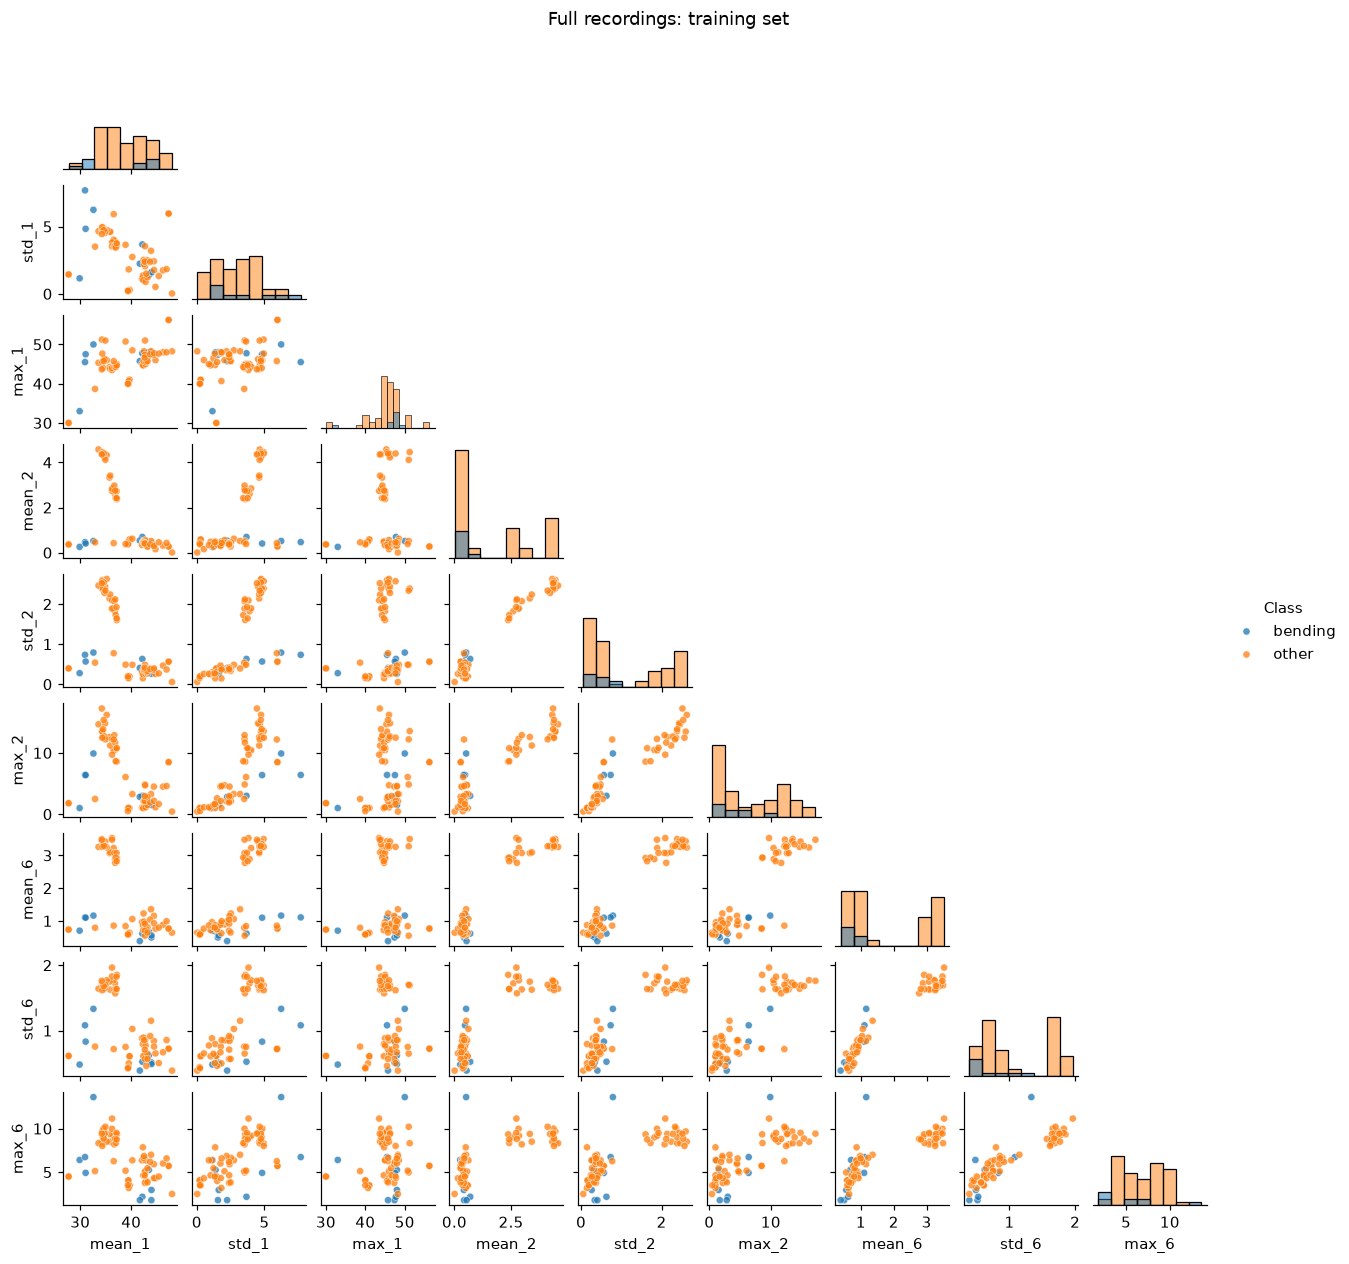

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_idx = instance_info.index[instance_info["split"].eq("train")]
test_idx = instance_info.index[instance_info["split"].eq("test")]
y_binary = instance_info["activity"].isin(["bending1", "bending2"]).astype(int)
y_train = y_binary.loc[train_idx]
y_test = y_binary.loc[test_idx]

plot_columns = [f"{stat}_{series}" for series in (1, 2, 6)
                for stat in ("mean", "std", "max")]
plot_full = features.loc[train_idx, plot_columns].copy()
plot_full["Class"] = np.where(y_train.eq(1), "bending", "other")
print(plot_full["Class"].value_counts())
grid = sns.pairplot(plot_full, vars=plot_columns, hue="Class",
                    corner=True, diag_kind="hist", height=1.25,
                    plot_kws={"s": 22, "alpha": 0.75})
grid.fig.suptitle("Full recordings: training set", y=1.02)
plt.show()

### 2(a)(ii) Two segments per recording

Splitting a recording doubles its time-series features while preserving the number of observations. The two halves are plotted separately for comparison with 2(a)(i).

The two halves show broadly similar bending/other overlap to the full recordings; splitting does not visibly improve separation much.

Two-half feature matrix: (88, 18)


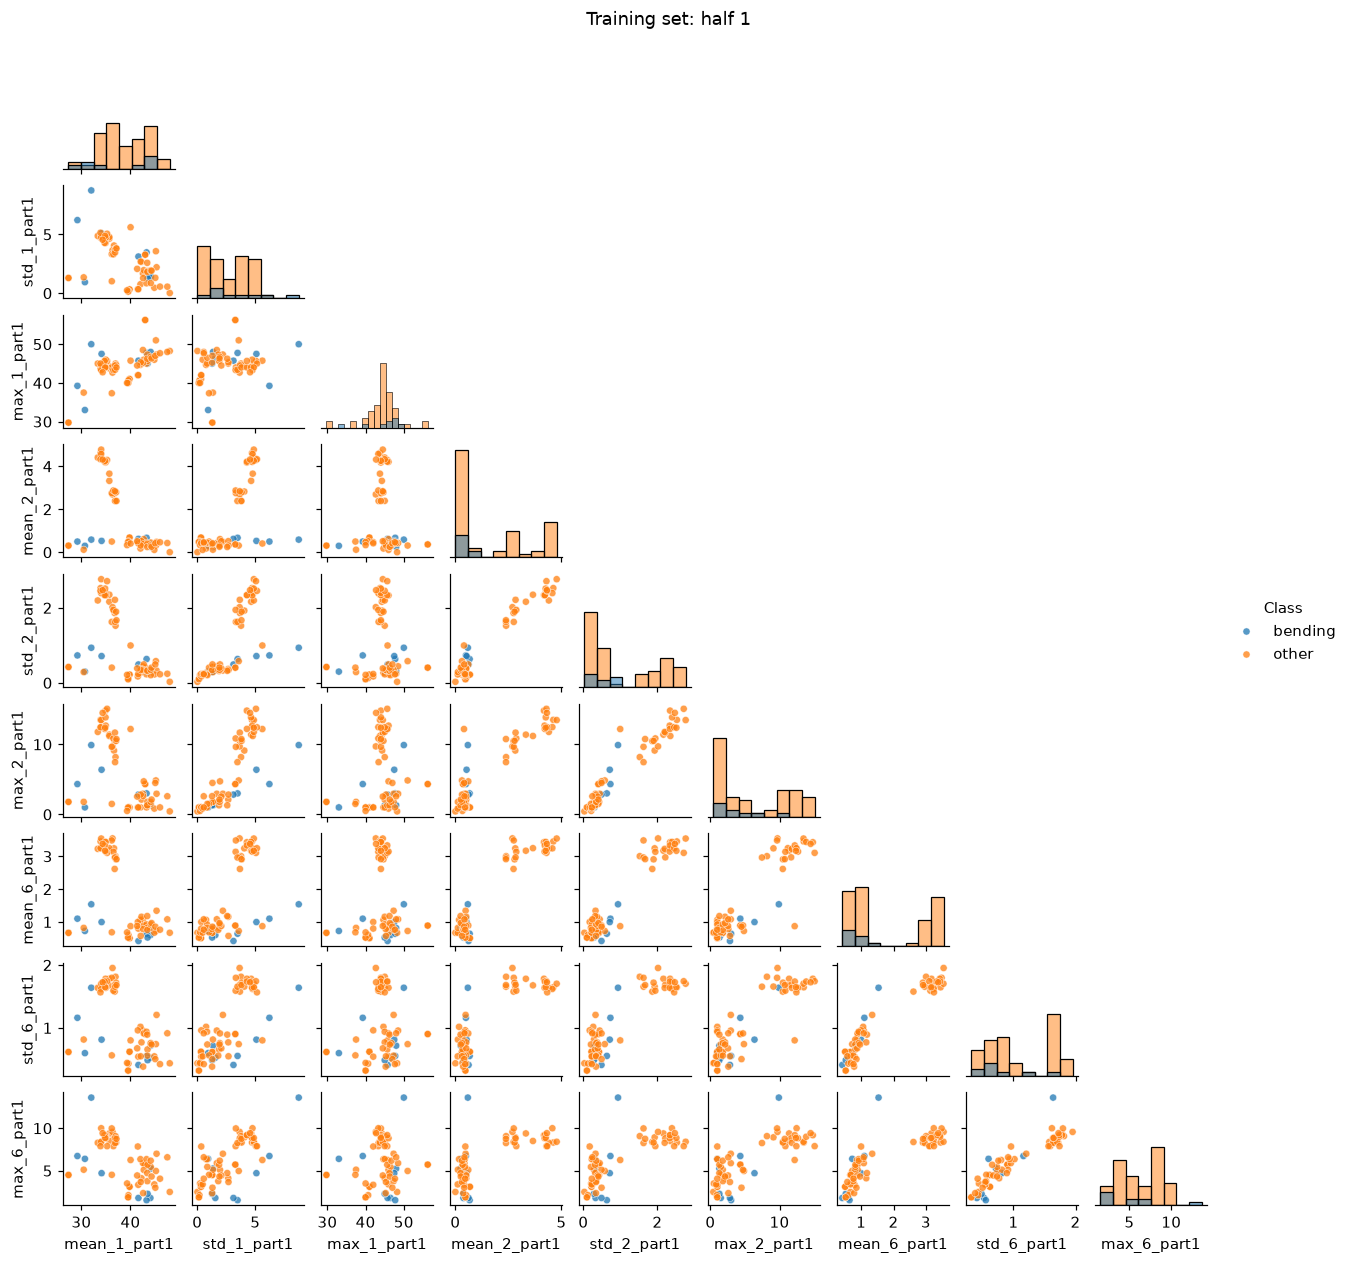

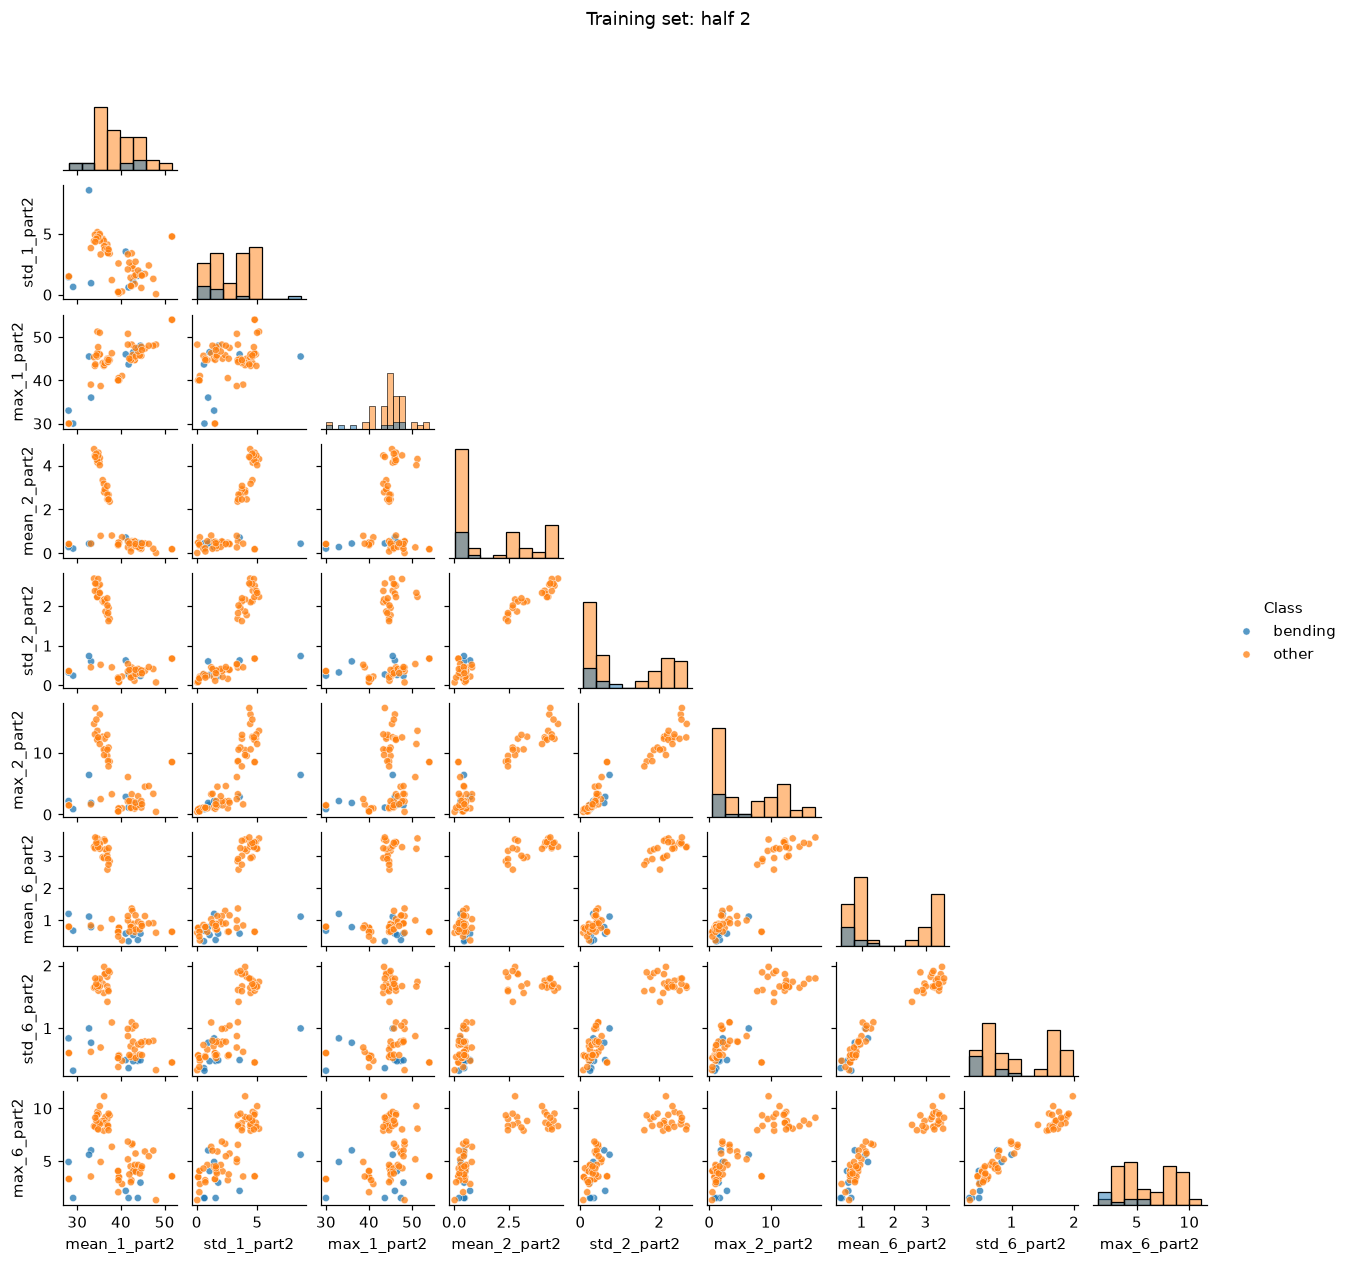

In [11]:
def segmented_features(number_of_segments, series_ids=(1, 2, 3, 4, 5, 6),
                       statistics=("min", "max", "mean", "median", "std", "q1", "q3")):
    rows = []
    for path in instance_info["path"]:
        recording = recordings[path]
        boundaries = np.linspace(0, len(recording), number_of_segments + 1,
                                 dtype=int)
        row = {}
        for part in range(number_of_segments):
            segment = recording.iloc[boundaries[part]:boundaries[part + 1]]
            for series_id in series_ids:
                values = segment[columns[series_id]]
                suffix = f"{series_id}_part{part + 1}"
                summary = {
                    "min": values.min(), "max": values.max(),
                    "mean": values.mean(), "median": values.median(),
                    "std": values.std(ddof=1),
                    "q1": values.quantile(0.25), "q3": values.quantile(0.75),
                }
                for stat in statistics:
                    row[f"{stat}_{suffix}"] = summary[stat]
        rows.append(row)
    return pd.DataFrame(rows, index=instance_info.index)

two_halves = segmented_features(2, series_ids=(1, 2, 6),
                                statistics=("mean", "std", "max"))
print("Two-half feature matrix:", two_halves.shape)
for part in (1, 2):
    part_columns = [f"{stat}_{series}_part{part}"
                    for series in (1, 2, 6)
                    for stat in ("mean", "std", "max")]
    plot_half = two_halves.loc[train_idx, part_columns].copy()
    plot_half["Class"] = np.where(y_train.eq(1), "bending", "other")
    grid = sns.pairplot(plot_half, vars=part_columns, hue="Class",
                        corner=True, diag_kind="hist", height=1.25,
                        plot_kws={"s": 22, "alpha": 0.75})
    grid.fig.suptitle(f"Training set: half {part}", y=1.02)
    plt.show()

### 2(a)(iii) Segment count and feature selection

For each $l=1,\ldots,20$, all seven HW3 statistics are extracted from all six series in every segment. Five-fold stratified validation selects $(l,p)$. Scaling and recursive feature elimination are fitted inside each training fold, so validation folds do not influence feature selection.

The wrong approach would select features before cross-validation or treat segments of one recording as independent observations; either would leak information across folds.

The candidate feature counts are shown in the code below.

In [13]:
from sklearn.base import clone
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

segment_tables = {l: segmented_features(l) for l in range(1, 21)}
binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
p_choices = (1, 2, 3, 6, 9, 12, 18, 24, 36)

def rfe_pipeline(p):
    return Pipeline([
        ("scale", StandardScaler()),
        ("select", RFE(LogisticRegression(solver="liblinear", C=100,
                                          max_iter=600),
                       n_features_to_select=p, step=0.5)),
        ("model", LogisticRegression(solver="liblinear", C=100,
                                     max_iter=600)),
    ])

binary_cv_rows = []
for l, table in segment_tables.items():
    X = table.loc[train_idx]
    for p in p_choices:
        if p > X.shape[1]:
            continue
        scores = cross_val_score(rfe_pipeline(p), X, y_train,
                                 cv=binary_cv, scoring="accuracy")
        binary_cv_rows.append({"l": l, "p": p,
                               "cv_accuracy": scores.mean(),
                               "cv_sd": scores.std(ddof=1)})

binary_cv_results = pd.DataFrame(binary_cv_rows).sort_values(
    ["cv_accuracy", "l", "p"], ascending=[False, True, True]
).reset_index(drop=True)
best_l = int(binary_cv_results.loc[0, "l"])
best_p = int(binary_cv_results.loc[0, "p"])
X_train_best = segment_tables[best_l].loc[train_idx]
X_test_best = segment_tables[best_l].loc[test_idx]
binary_model = rfe_pipeline(best_p).fit(X_train_best, y_train)
selected_names = X_train_best.columns[
    binary_model.named_steps["select"].support_
]
print("Best l, p and CV accuracy:", best_l, best_p,
      round(binary_cv_results.loc[0, "cv_accuracy"], 4))
print("Selected features:", selected_names.tolist())
display(binary_cv_results.head(10).round(4))

Best l, p and CV accuracy: 1 2 0.9857
Selected features: ['min_5_part1', 'max_5_part1']


,l,p,cv_accuracy,cv_sd
0,1,2,0.9857,0.0319
1,1,3,0.9857,0.0319
2,3,1,0.9857,0.0319
3,6,6,0.9857,0.0319
4,1,24,0.9714,0.0391
5,1,36,0.9714,0.0391
6,2,3,0.9714,0.0391
7,3,2,0.9714,0.0391
8,2,2,0.9703,0.0407
9,1,6,0.9571,0.0639


In [14]:
import statsmodels.api as sm
import warnings

scaled_train = binary_model.named_steps["scale"].transform(X_train_best)
selected_train = scaled_train[:, binary_model.named_steps["select"].support_]
glm_X = sm.add_constant(selected_train, has_constant="add")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    glm_result = sm.GLM(y_train.to_numpy(), glm_X,
                        family=sm.families.Binomial()).fit(maxiter=200)
parameter_table = pd.DataFrame({
    "coefficient": glm_result.params,
    "p_value": glm_result.pvalues,
}, index=["intercept", *selected_names])
display(parameter_table.round(5))

,coefficient,p_value
intercept,-422.73805,0.99870
min_5_part1,380.73713,0.99871
max_5_part1,283.10750,0.99871


### 2(a)(iv-v) Training diagnostics and held-out test

The reported coefficients and p-values are from an unpenalized logistic refit on the features selected by RFE. These post-selection p-values are descriptive. The classifier is evaluated on the untouched test recordings, segmented with the same $l$.

The selected RFE model has 98.6% cross-validation accuracy and 89.5% test accuracy (17/19).

RFE logistic: training accuracy: 0.9855 AUC: 1.0


,predicted other,predicted bending
actual other,60,0
actual bending,1,8


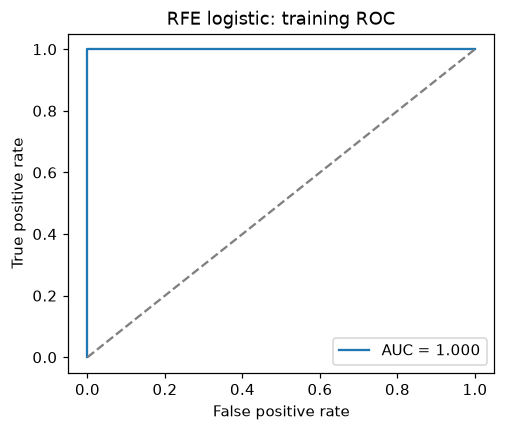

RFE logistic: test accuracy: 0.8947 AUC: 0.9


,predicted other,predicted bending
actual other,14,1
actual bending,1,3


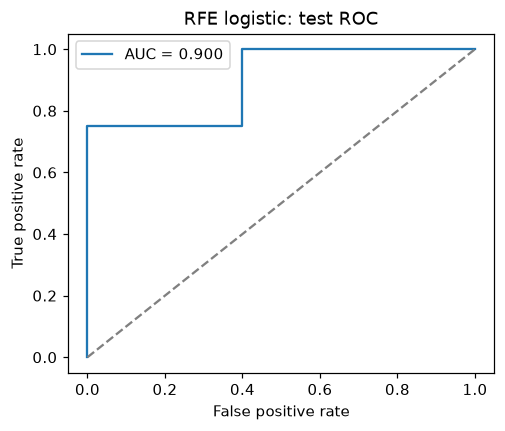

CV accuracy: 0.9857
Test accuracy: 0.8947
Coefficient range: [-422.738  380.737]


In [16]:
def binary_report(model, X, y, title):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    matrix = confusion_matrix(y, predictions, labels=[0, 1])
    auc = roc_auc_score(y, probabilities)
    print(title, "accuracy:", round(accuracy_score(y, predictions), 4),
          "AUC:", round(auc, 4))
    display(pd.DataFrame(matrix, index=["actual other", "actual bending"],
                         columns=["predicted other", "predicted bending"]))
    fpr, tpr, _ = roc_curve(y, probabilities)
    plt.figure(figsize=(5, 4))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title + " ROC")
    plt.legend()
    plt.show()
    return {"accuracy": accuracy_score(y, predictions), "auc": auc,
            "confusion": matrix, "probabilities": probabilities}

binary_train_result = binary_report(binary_model, X_train_best, y_train,
                                    "RFE logistic: training")
binary_test_result = binary_report(binary_model, X_test_best, y_test,
                                   "RFE logistic: test")
print("CV accuracy:", round(binary_cv_results.loc[0, "cv_accuracy"], 4))
print("Test accuracy:", round(binary_test_result["accuracy"], 4))
print("Coefficient range:",
      np.round([parameter_table["coefficient"].min(),
                parameter_table["coefficient"].max()], 3))

### 2(a)(vi-vii) Separation and class imbalance

The training set contains only nine bending recordings and sixty others. A balanced case-control sample is fitted on the training set, and its log-odds intercept is adjusted back to the original training prevalence.

Near-perfect training classification and extreme fitted coefficients indicate near-separation. The resulting unpenalized p-values are unstable and should not be used as evidence of significance.

Training class counts: {0: 60, 1: 9}
Near-certain original training probabilities: 42
Case-control training accuracy: 0.9855 AUC: 1.0


,predicted other,predicted bending
actual other,60,0
actual bending,1,8


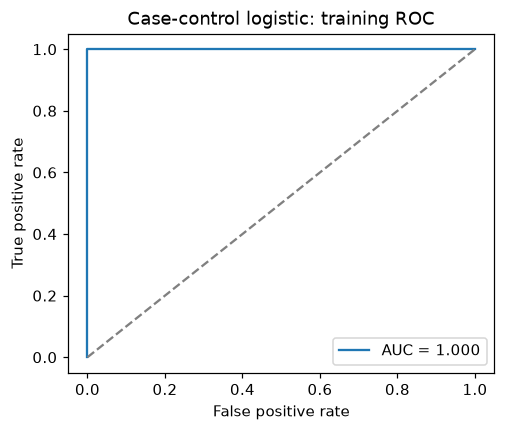

Case-control intercept correction: -1.8971
Case-control test accuracy: 0.9474 AUC: 0.9


,predicted other,predicted bending
actual other,15,0
actual bending,1,3


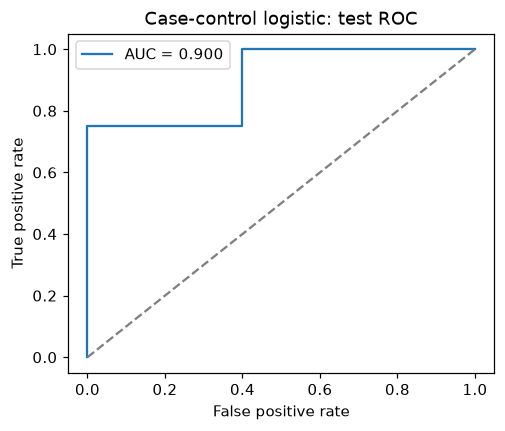

In [18]:
from scipy.special import expit, logit

print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Near-certain original training probabilities:",
      int(((binary_train_result["probabilities"] < 1e-4) |
           (binary_train_result["probabilities"] > 1 - 1e-4)).sum()))

rng = np.random.default_rng(552)
negative_positions = np.flatnonzero(y_train.to_numpy() == 0)
positive_positions = np.flatnonzero(y_train.to_numpy() == 1)
sampled_positive = rng.choice(positive_positions, size=len(negative_positions),
                              replace=True)
balanced_positions = np.r_[negative_positions, sampled_positive]
rng.shuffle(balanced_positions)

case_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(solver="liblinear", C=100, max_iter=600)),
])
case_X = X_train_best.loc[:, selected_names]
case_model.fit(case_X.iloc[balanced_positions],
               y_train.iloc[balanced_positions])
original_prior = y_train.mean()
sampled_prior = y_train.iloc[balanced_positions].mean()

def corrected_case_probability(X):
    sampled_probability = case_model.predict_proba(X.loc[:, selected_names])[:, 1]
    offset = logit(original_prior) - logit(sampled_prior)
    return expit(logit(np.clip(sampled_probability, 1e-12, 1 - 1e-12)) + offset)

case_prob_train = corrected_case_probability(X_train_best)
case_pred_train = (case_prob_train >= 0.5).astype(int)
case_auc_train = roc_auc_score(y_train, case_prob_train)
print("Case-control training accuracy:",
      round(accuracy_score(y_train, case_pred_train), 4),
      "AUC:", round(case_auc_train, 4))
display(pd.DataFrame(confusion_matrix(y_train, case_pred_train, labels=[0, 1]),
                     index=["actual other", "actual bending"],
                     columns=["predicted other", "predicted bending"]))
fpr, tpr, _ = roc_curve(y_train, case_prob_train)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {case_auc_train:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Case-control logistic: training ROC")
plt.legend()
plt.show()
print("Case-control intercept correction:", round(float(logit(original_prior) - logit(sampled_prior)), 4))

case_prob_test = corrected_case_probability(X_test_best)
case_pred_test = (case_prob_test >= 0.5).astype(int)
case_auc_test = roc_auc_score(y_test, case_prob_test)
print("Case-control test accuracy:",
      round(accuracy_score(y_test, case_pred_test), 4),
      "AUC:", round(case_auc_test, 4))
display(pd.DataFrame(confusion_matrix(y_test, case_pred_test, labels=[0, 1]),
                     index=["actual other", "actual bending"],
                     columns=["predicted other", "predicted bending"]))
fpr, tpr, _ = roc_curve(y_test, case_prob_test)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {case_auc_test:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Case-control logistic: test ROC")
plt.legend()
plt.show()

### 2(b)(i) L1-penalized binary logistic regression

Five-fold validation jointly selects the segment count $l$ and inverse penalty strength $C$. Scaling stays inside the validation pipeline.

Best l, C and CV accuracy: 1 3.0 0.9714
Nonzero coefficients: 8


,l,C,cv_accuracy
0,1,3.0,0.9714
1,3,0.3,0.9714
2,12,3.0,0.9714
3,19,3.0,0.9571
4,20,3.0,0.9571
5,1,0.3,0.9571
6,3,3.0,0.9571
7,12,0.3,0.9571
8,18,3.0,0.9571
9,19,0.3,0.9571


L1 logistic: training accuracy: 1.0 AUC: 1.0


,predicted other,predicted bending
actual other,60,0
actual bending,0,9


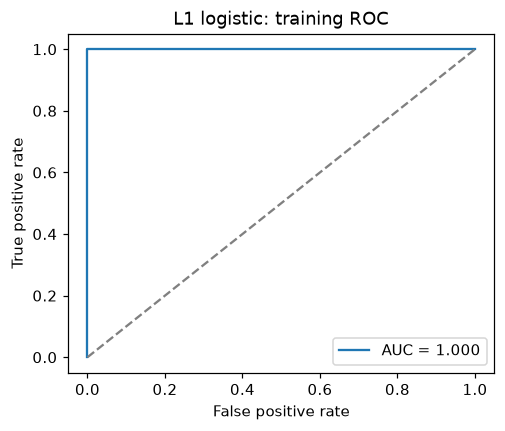

L1 logistic: test accuracy: 1.0 AUC: 1.0


,predicted other,predicted bending
actual other,15,0
actual bending,0,4


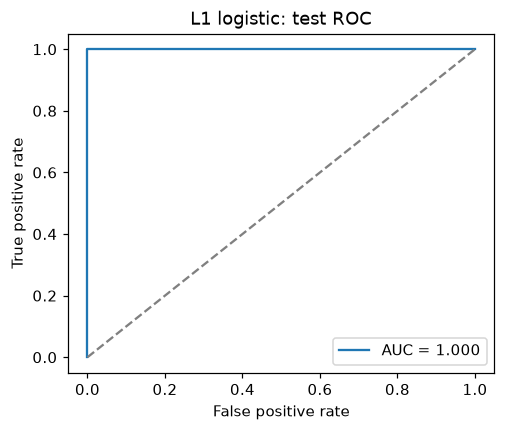

In [20]:
def l1_binary_pipeline(C):
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(solver="liblinear", l1_ratio=1,
                                     C=C, max_iter=1000)),
    ])

C_choices = (0.03, 0.3, 3.0)
l1_rows = []
for l, table in segment_tables.items():
    X = table.loc[train_idx]
    for C in C_choices:
        scores = cross_val_score(l1_binary_pipeline(C), X, y_train,
                                 cv=binary_cv, scoring="accuracy")
        l1_rows.append({"l": l, "C": C, "cv_accuracy": scores.mean()})

l1_cv_results = pd.DataFrame(l1_rows).sort_values(
    ["cv_accuracy", "l", "C"], ascending=[False, True, True]
).reset_index(drop=True)
l1_l = int(l1_cv_results.loc[0, "l"])
l1_C = float(l1_cv_results.loc[0, "C"])
l1_model = l1_binary_pipeline(l1_C).fit(
    segment_tables[l1_l].loc[train_idx], y_train
)
print("Best l, C and CV accuracy:", l1_l, l1_C,
      round(l1_cv_results.loc[0, "cv_accuracy"], 4))
print("Nonzero coefficients:",
      int(np.count_nonzero(l1_model.named_steps["model"].coef_)))
display(l1_cv_results.head(10).round(4))
l1_train_result = binary_report(l1_model,
                                segment_tables[l1_l].loc[train_idx],
                                y_train, "L1 logistic: training")
l1_test_result = binary_report(l1_model,
                               segment_tables[l1_l].loc[test_idx],
                               y_test, "L1 logistic: test")

### 2(b)(ii) Binary method comparison

L1 shrinkage performs selection within one penalized fit; RFE repeatedly refits a model. The comparison below uses the held-out test set only after both methods were selected by cross-validation.

L1 performs better on the test set (19/19 vs. 17/19) and is easier to implement; RFE has slightly higher cross-validation accuracy.

In [22]:
binary_comparison = pd.DataFrame({
    "method": ["RFE logistic", "L1 logistic"],
    "CV accuracy": [binary_cv_results.loc[0, "cv_accuracy"],
                    l1_cv_results.loc[0, "cv_accuracy"]],
    "test accuracy": [binary_test_result["accuracy"],
                      l1_test_result["accuracy"]],
    "test AUC": [binary_test_result["auc"], l1_test_result["auc"]],
})
display(binary_comparison.round(4))

,method,CV accuracy,test accuracy,test AUC
0,RFE logistic,0.9857,0.8947,0.9
1,L1 logistic,0.9714,1.0000,1.0


### 2(c)(i) Seven-class L1 multinomial logistic regression

The seven source folders are the class labels. Four-fold stratified validation selects $l$ and $C$; each validation fold contains one of the four bending2 training recordings.

Best l, C and CV accuracy: 1 3.0 0.8987
Test error: 0.1053


,l,C,cv_accuracy
0,1,3.0,0.8987
1,2,0.3,0.8546
2,1,0.3,0.8415
3,3,0.3,0.8407
4,3,3.0,0.8407
5,5,3.0,0.8399
6,2,3.0,0.8391
7,9,0.3,0.8276
8,7,3.0,0.8268
9,6,3.0,0.8260


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,2,0,0,0,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,1,0,2,0
walking,0,0,0,0,0,0,3


Macro one-vs-rest AUC: 0.997


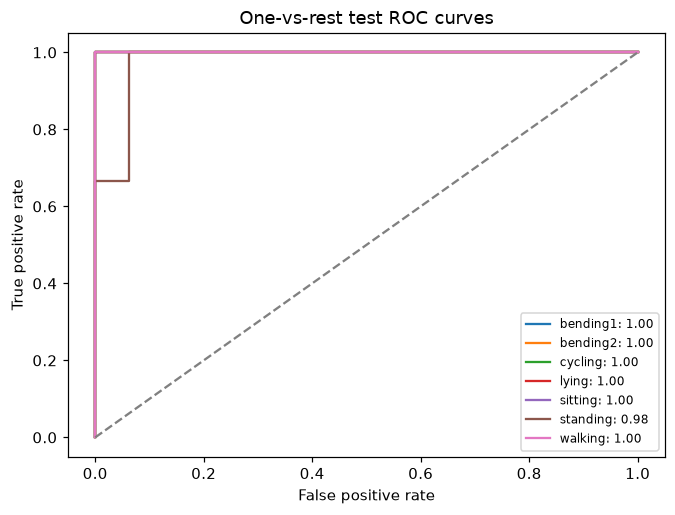

In [24]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize

y_multiclass = instance_info["activity"]
y_multi_train = y_multiclass.loc[train_idx]
y_multi_test = y_multiclass.loc[test_idx]
multi_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=552)

def multinomial_pipeline(C):
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(solver="saga", l1_ratio=1,
                                     C=C, max_iter=1200, tol=0.01,
                                     random_state=552)),
    ])

multi_rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    warnings.simplefilter("ignore", ConvergenceWarning)
    for l, table in segment_tables.items():
        X = table.loc[train_idx]
        for C in C_choices:
            scores = cross_val_score(multinomial_pipeline(C), X,
                                     y_multi_train, cv=multi_cv,
                                     scoring="accuracy")
            multi_rows.append({"l": l, "C": C,
                               "cv_accuracy": scores.mean()})

multi_cv_results = pd.DataFrame(multi_rows).sort_values(
    ["cv_accuracy", "l", "C"], ascending=[False, True, True]
).reset_index(drop=True)
multi_l = int(multi_cv_results.loc[0, "l"])
multi_C = float(multi_cv_results.loc[0, "C"])
multi_model = multinomial_pipeline(multi_C).fit(
    segment_tables[multi_l].loc[train_idx], y_multi_train
)
multi_X_test = segment_tables[multi_l].loc[test_idx]
multi_pred = multi_model.predict(multi_X_test)
multi_prob = multi_model.predict_proba(multi_X_test)
classes = multi_model.named_steps["model"].classes_
multi_error = 1 - accuracy_score(y_multi_test, multi_pred)
print("Best l, C and CV accuracy:", multi_l, multi_C,
      round(multi_cv_results.loc[0, "cv_accuracy"], 4))
print("Test error:", round(multi_error, 4))
display(multi_cv_results.head(10).round(4))
display(pd.DataFrame(confusion_matrix(y_multi_test, multi_pred,
                                      labels=classes),
                     index=classes, columns=classes))
multi_auc = roc_auc_score(y_multi_test, multi_prob,
                          labels=classes, multi_class="ovr",
                          average="macro")
print("Macro one-vs-rest AUC:", round(multi_auc, 4))
binary_indicator = label_binarize(y_multi_test, classes=classes)
plt.figure(figsize=(7, 5))
for j, name in enumerate(classes):
    fpr, tpr, _ = roc_curve(binary_indicator[:, j], multi_prob[:, j])
    plt.plot(fpr, tpr, label=f"{name}: {roc_auc_score(binary_indicator[:, j], multi_prob[:, j]):.2f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("One-vs-rest test ROC curves")
plt.legend(fontsize=8)
plt.show()

### 2(c)(ii) Gaussian and multinomial Naive Bayes

Each model selects its segment count by four-fold validation. StandardScaler is fitted within each fold for GaussianNB; MinMaxScaler keeps MultinomialNB inputs nonnegative. The signal summaries are continuous measurements rather than event counts. Confusion matrices and one-vs-rest ROC curves are reported for both models.

GaussianNB test confusion matrix:


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,0,0,0,2,0,0,0
bending2,0,0,0,1,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,1,1,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


Macro one-vs-rest AUC: 0.8461


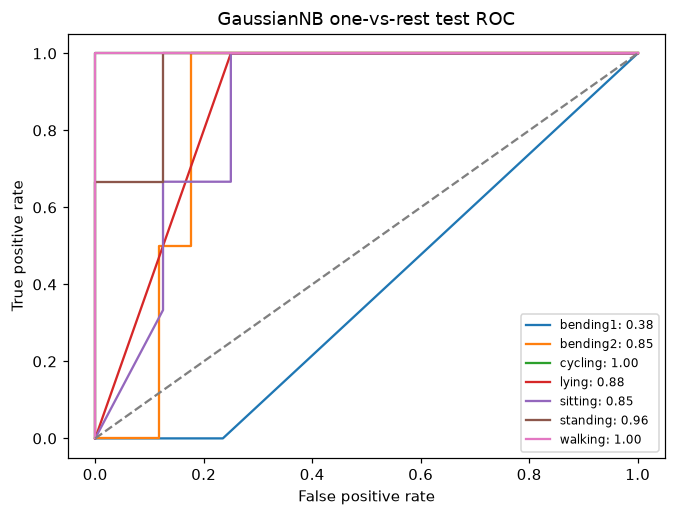

MultinomialNB test confusion matrix:


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,1,0,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,1,0,2,0,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


Macro one-vs-rest AUC: 0.969


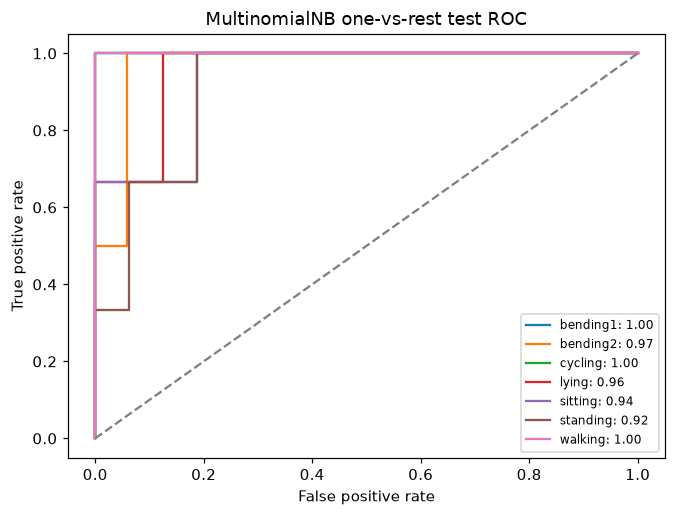

,method,l,CV accuracy,test error,macro AUC
0,GaussianNB,2,0.8554,0.3684,0.8461
1,MultinomialNB,5,0.7541,0.2632,0.9690


In [26]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

nb_estimators = {
    "GaussianNB": Pipeline([("scale", StandardScaler()),
                            ("model", GaussianNB())]),
    "MultinomialNB": Pipeline([("scale", MinMaxScaler(clip=True)),
                               ("model", MultinomialNB())]),
}

nb_cv_rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    for method, estimator in nb_estimators.items():
        for l, table in segment_tables.items():
            scores = cross_val_score(estimator, table.loc[train_idx],
                                     y_multi_train, cv=multi_cv,
                                     scoring="accuracy")
            nb_cv_rows.append({"method": method, "l": l,
                               "cv_accuracy": scores.mean()})

nb_cv_results = pd.DataFrame(nb_cv_rows)

def plot_nb_roc(y, probabilities, class_names, title):
    indicators = label_binarize(y, classes=class_names)
    plt.figure(figsize=(7, 5))
    for j, name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(indicators[:, j], probabilities[:, j])
        area = roc_auc_score(indicators[:, j], probabilities[:, j])
        plt.plot(fpr, tpr, label=f"{name}: {area:.2f}")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title + " one-vs-rest test ROC")
    plt.legend(fontsize=8)
    plt.show()

nb_results = []
for method, estimator in nb_estimators.items():
    ranked = nb_cv_results[nb_cv_results["method"].eq(method)].sort_values(
        ["cv_accuracy", "l"], ascending=[False, True]
    )
    chosen_l = int(ranked.iloc[0]["l"])
    fitted = clone(estimator).fit(segment_tables[chosen_l].loc[train_idx],
                                  y_multi_train)
    predictions = fitted.predict(segment_tables[chosen_l].loc[test_idx])
    test_error = 1 - accuracy_score(y_multi_test, predictions)
    probabilities = fitted.predict_proba(segment_tables[chosen_l].loc[test_idx])
    nb_auc = roc_auc_score(y_multi_test, probabilities, labels=classes,
                           multi_class="ovr", average="macro")
    nb_results.append({"method": method, "l": chosen_l,
                       "CV accuracy": ranked.iloc[0]["cv_accuracy"],
                       "test error": test_error, "macro AUC": nb_auc})
    print(method, "test confusion matrix:")
    display(pd.DataFrame(confusion_matrix(y_multi_test, predictions,
                                          labels=classes),
                         index=classes, columns=classes))
    print("Macro one-vs-rest AUC:", round(nb_auc, 4))
    plot_nb_roc(y_multi_test, probabilities, classes, method)

nb_comparison = pd.DataFrame(nb_results)
display(nb_comparison.round(4))

### 2(c)(iii) Multiclass comparison

Each confusion-matrix row is the true class and each column is the predicted class. For multiclass ROC, each class is compared with all remaining classes; the macro AUC averages these one-vs-rest AUCs. Methods are compared by held-out test error and macro AUC. With only nineteen test recordings, small differences should be interpreted cautiously. [ROC definition](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html).

L1 multinomial has the lowest test error (2/19), compared with 5/19 for MultinomialNB and 7/19 for GaussianNB.

In [28]:
multi_comparison = pd.concat([
    pd.DataFrame([{"method": "L1 multinomial", "l": multi_l,
                   "CV accuracy": multi_cv_results.loc[0, "cv_accuracy"],
                   "test error": multi_error, "macro AUC": multi_auc}]),
    nb_comparison,
], ignore_index=True)
display(multi_comparison.sort_values("test error").round(4))
lowest_error = multi_comparison["test error"].min()
best_methods = multi_comparison.loc[
    multi_comparison["test error"].eq(lowest_error), "method"
].tolist()
print("Lowest test error:", round(lowest_error, 4),
      "Method(s):", ", ".join(best_methods))

,method,l,CV accuracy,test error,macro AUC
0,L1 multinomial,1,0.8987,0.1053,0.9970
2,MultinomialNB,5,0.7541,0.2632,0.9690
1,GaussianNB,2,0.8554,0.3684,0.8461


Lowest test error: 0.1053 Method(s): L1 multinomial


## 3. ISLR 4.8.3

With prior $\pi_k$ and $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$, the Bayes classifier maximizes the log-posterior score

$$
\begin{aligned}
\delta_k(x)
&=\log\pi_k-\frac12\log\sigma_k^2-\frac{(x-\mu_k)^2}{2\sigma_k^2}\\
&=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}-\frac12\log\sigma_k^2+\log\pi_k.
\end{aligned}
$$

For classes with different variances, $\delta_k(x)-\delta_j(x)$ has a nonzero $x^2$ coefficient, so their decision boundary is quadratic. If all variances are equal, the quadratic terms cancel and the classifier reduces to linear LDA.

## 4. ISLR 4.8.7

Let $D$ denote issuing a dividend. Bayes' theorem gives

$$
\begin{aligned}
P(D\mid X=4)
&=\frac{0.8\,f(4\mid D)}{0.8\,f(4\mid D)+0.2\,f(4\mid D^c)}\\
&=\frac{0.8e^{-(4-10)^2/(2\cdot36)}}
{0.8e^{-(4-10)^2/(2\cdot36)}+0.2e^{-(4-0)^2/(2\cdot36)}}\\
&=\frac{0.8e^{-1/2}}{0.8e^{-1/2}+0.2e^{-2/9}}
\approx 0.75185.
\end{aligned}
$$

The predicted probability is **about 75.2%**.